In [17]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "dataset_analysis/data/"

features = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry",
    "fractal_dimension"
]
columns = ["id", "diagnosis"] + [
    f"{feature}_{version}"
    for version in ["mean", "se", "worst"]
    for feature in features
]

DATA_DIR = "/content/drive/MyDrive/wdbc/"
if not os.path.isdir(DATA_DIR):
    print("Folders in My Drive:", os.listdir("/content/drive/MyDrive"))
    raise FileNotFoundError("Create a folder named wdbc directly inside My Drive.")

print("Files in Google Drive folder:", os.listdir(DATA_DIR))

df = pd.read_csv(DATA_DIR + "wdbc.data", header=None, names=columns)

Files in Google Drive folder: ['wdbc.data', 'wdbc.names']


In [19]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate IDs:", df["id"].duplicated().sum())

print("\nDiagnosis counts:")
print(df["diagnosis"].value_counts())

print("\nDiagnosis percentages:")
print((df["diagnosis"].value_counts(normalize=True) * 100).round(1))

Shape: (569, 32)
Missing values: 0
Duplicate IDs: 0

Diagnosis counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Diagnosis percentages:
diagnosis
B    62.7
M    37.3
Name: proportion, dtype: float64


In [20]:
selected_features = [
    "radius_mean", "texture_mean", "area_mean", "smoothness_mean",
    "concavity_mean", "concave_points_mean"
]
comparison = df.groupby("diagnosis")[selected_features].agg(["mean", "median"]).round(3)
comparison

radius_mean         texture_mean        area_mean         \
                 mean  median         mean median      mean median   
diagnosis                                                            
B              12.147  12.200       17.915  17.39   462.790  458.4   
M              17.463  17.325       21.605  21.46   978.376  932.0   

          smoothness_mean        concavity_mean        concave_points_mean  \
                     mean median           mean median                mean   
diagnosis                                                                    
B                   0.092  0.091          0.046  0.037               0.026   
M                   0.103  0.102          0.161  0.151               0.088   

                  
          median  
diagnosis         
B          0.023  
M          0.086

In [21]:
simple_names = {
    "radius": "Cell size (radius)",
    "texture": "Surface texture",
    "perimeter": "Cell boundary (perimeter)",
    "area": "Cell area",
    "smoothness": "Boundary smoothness",
    "compactness": "Cell compactness",
    "concavity": "Boundary indentation",
    "concave_points": "Indented boundary points",
    "symmetry": "Cell symmetry",
    "fractal_dimension": "Boundary complexity"
}

simple_summary = pd.DataFrame({
    "measurement": [simple_names[f] for f in features],
    "average": [df[f"{f}_mean"].mean() for f in features],
    "median": [df[f"{f}_mean"].median() for f in features],
    "lowest": [df[f"{f}_mean"].min() for f in features],
    "highest": [df[f"{f}_mean"].max() for f in features]
})

simple_summary.round(3)

,measurement,average,median,lowest,highest
0,Cell size (radius),14.127,13.370,6.981,28.110
1,Surface texture,19.290,18.840,9.710,39.280
2,Cell boundary (perimeter),91.969,86.240,43.790,188.500
3,Cell area,654.889,551.100,143.500,2501.000
4,Boundary smoothness,0.096,0.096,0.053,0.163
5,Cell compactness,0.104,0.093,0.019,0.345
6,Boundary indentation,0.089,0.062,0.000,0.427
7,Indented boundary points,0.049,0.034,0.000,0.201
8,Cell symmetry,0.181,0.179,0.106,0.304
9,Boundary complexity,0.063,0.062,0.050,0.097


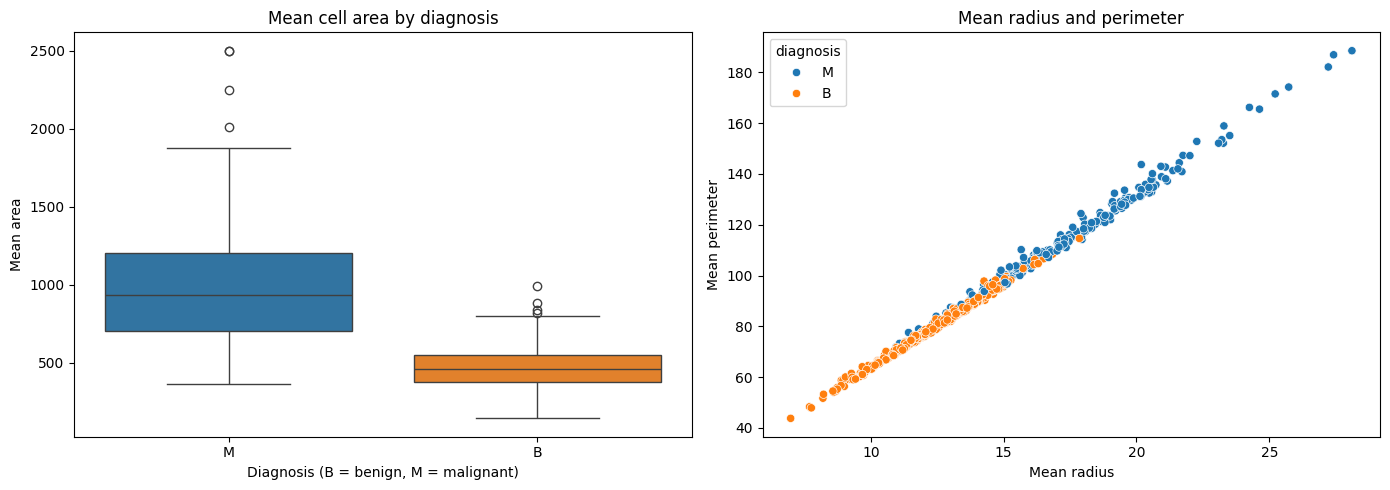

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="diagnosis", y="area_mean", hue="diagnosis", ax=axes[0], legend=False)
axes[0].set_title("Mean cell area by diagnosis")
axes[0].set_xlabel("Diagnosis (B = benign, M = malignant)")
axes[0].set_ylabel("Mean area")

sns.scatterplot(data=df, x="radius_mean", y="perimeter_mean", hue="diagnosis", ax=axes[1])
axes[1].set_title("Mean radius and perimeter")
axes[1].set_xlabel("Mean radius")
axes[1].set_ylabel("Mean perimeter")

plt.tight_layout()
plt.show()

# Dataset Value Stats
The dataset has no missing values and no duplicate ids. It contains 357 benign samples (62.7%) and 212 malignant samples (37.3%). Each sample has information like cell radius, texture, perimeter, area, smoothness, compactness, concavity, symmetry, and fractal dimension. These measurements recorded as mean and standard error, including the worst case values.

# Graphical Analysis
Based on the two graphs generated through seaborn and matplotlib, we can see that malignant samples are generally larger and more irregular than benign samples. The avg cell size for malignant is ~980 while only ~460 for benign samples. Malignant samples are also generally larger in other size measurements.

# Question
1. How much overlap between benign and malignant samples in size are there?